# 05 · Compare clean metadata models and feature sets

Reproduce the original five-model and seven-feature-set comparisons. Read ranking, probability error, fold variation, nonlinear age and saved model diagnostics together.

Read the stages in numerical order. Training uses separate, explicitly invoked runners; executing this notebook only loads development data and saved artifacts.

Original notebooks, images, checkpoints and results remain available. The reserved test is outside this workflow.

**Original methods and figure reference:** [05_metadata_models.ipynb](../Subset/05_metadata_models.ipynb). Read [method coverage](METHOD_COVERAGE.md) for retained methods and declared adaptations.

## Load the frozen clean development dataset

In [1]:
NOTEBOOK_STAGE = '05_metadata_models'
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from melanoma_detection.development_dataset import load_development_dataset, load_preserved_inner_memberships
from melanoma_detection.dedup_workflow import load_context, latest_evaluation, load_clean_scores, load_image_report, load_uncertainty_report, read_json, project_path, DIRECTORY, METADATA_SUITE, UNCERTAINTY
get_ipython().run_line_magic("matplotlib", "inline")
MANIFEST = "data/subset/processed/dedup_v1/dataset_manifest.json"
data, dataset_identity = load_development_dataset(ROOT, dataset_manifest=MANIFEST)
context = load_context(ROOT)
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
FIGURE_DIR = ROOT / DIRECTORY / "figures" / NOTEBOOK_STAGE
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def finish_figure(figure, filename):
    if not filename or Path(filename).name != filename:
        raise ValueError("Figure name must be a simple stem.")
    figure.savefig(FIGURE_DIR / (filename + ".png"), dpi=180, bbox_inches="tight")
    figure.savefig(FIGURE_DIR / (filename + ".pdf"), bbox_inches="tight")
    plt.show()
    plt.close(figure)

_score_bundle = None
def score_bundle():
    global _score_bundle
    if _score_bundle is None:
        _score_bundle = load_clean_scores(ROOT)
    return _score_bundle
display(pd.DataFrame([{"Images": len(data), "Malignant images": int(data.target.sum()),
    "Patients": data.patient_id.nunique(), "Malignant patients": data.loc[data.target.eq(1), "patient_id"].nunique()}]))
display(Markdown("**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training."))

def show_saved_table(relative, limit=30):
    path = project_path(ROOT, relative)
    if not path.exists():
        display(Markdown("**Pending:** " + relative + ". No results are inferred from unfinished runs."))
        return pd.DataFrame()
    table = pd.read_csv(path)
    display(table.head(limit))
    if len(table) > limit:
        display(Markdown(f"Showing {limit} of {len(table)} rows; the complete CSV is saved."))
    return table

def comparison_table():
    evaluation = latest_evaluation(ROOT)
    if "output_directory" not in evaluation:
        display(Markdown("**Pending:** clean evaluation has not been generated."))
        return pd.DataFrame()
    path = project_path(ROOT, evaluation["output_directory"] + "/model_comparison.csv")
    return pd.read_csv(path)

def model_chart(table, title):
    if table.empty:
        display(Markdown("**Pending:** no verified scores are available for this stage."))
        return
    table = table.sort_values("average_precision")
    fig, ax = plt.subplots(figsize=(9, max(3.2, .38 * len(table) + 1.5)), layout="constrained")
    ax.barh(table.model, table.average_precision, color="#276b91")
    ax.set(title=title, xlabel="Unweighted mean outer-fold average precision", xlim=(0, max(.1, float(table.average_precision.max()) * 1.25)))
    finish_figure(fig, "model_comparison_ap")

def pilot_report(run_id):
    directory = ROOT / "results/image_d1_runs" / run_id
    path = directory / "summary.json"
    summary = read_json(path) if path.exists() else {"status": "pending"}
    if summary.get("status") == "complete":
        manifest = read_json(directory / "run_manifest.json")
        if manifest["dataset_identity"] != dataset_identity:
            raise ValueError("Pilot belongs to another dataset.")
        from melanoma_detection.development_dataset import sha256_file
        for relative, digest in summary["artifact_sha256"].items():
            artifact = (directory / relative).resolve()
            if not artifact.is_relative_to(directory.resolve()) or sha256_file(artifact) != digest:
                raise ValueError("Completed pilot artifact changed.")
    return directory, summary


,Images,Malignant images,Patients,Malignant patients
0,6706,127,422,88


**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training.

## 1. Check matched records and the fixed model specifications

The fixed spline uses four quantile knots, cubic degree, training-median age imputation and scaling; the classifier has C=1. Trees retain categorical-age encoding. Forest settings are 300 trees/depth 8/minimum leaf 5; XGBoost uses 200 trees/depth 3/learning rate 0.05. These are historical starting settings, with no outer-label tuning in this notebook.

In [2]:
import json
from melanoma_detection.metadata_evaluation import decision_metrics
from melanoma_detection.dedup_notebook_metadata import (
    LABELS, COLORS, saved_metadata, metric_table, curve_figure, metric_bar_figure,
    cutoff_table, confusion_figure, estimator_diagnostics, reliability_table,
    decision_intervals, subgroup_diagnostics, save_metadata_table,
)
bundle = score_bundle()
frame, scores = bundle["expected"], bundle["scores"]
meta = saved_metadata(ROOT, bundle)
display(pd.DataFrame([{"Dataset identity": bundle["identity"]["dataset_identity"],
    "New CPU fits": meta["receipt"]["executed_fits"], "Reused clean fits": meta["receipt"]["reused_fits"],
    "Images with matching predictions": len(frame), "Reserved test loaded": False}]))

names = ["dummy", "categorical_logistic", "spline_raw", "random_forest", "xgboost"]
metrics = metric_table(frame, scores, names)
display(pd.DataFrame([{"Model": LABELS[name], "Features": "Age, sex, site", "Preprocessing fit": "Outer training patients only", "OOF images": len(frame)} for name in names]))
display(pd.DataFrame([meta["core"]["specification"]["spline"]]).T)

,Dataset identity,New CPU fits,Reused clean fits,Images with matching predictions,Reserved test loaded
0,0562e7bb898ab69d2e5ac7fcf50bf6e9b80663362af4ae...,695,60,6706,False


,Model,Features,Preprocessing fit,OOF images
0,Training-prevalence dummy,"Age, sex, site",Outer training patients only,6706
1,Categorical-age logistic,"Age, sex, site",Outer training patients only,6706
2,Fixed spline,"Age, sex, site",Outer training patients only,6706
3,Random forest,"Age, sex, site",Outer training patients only,6706
4,XGBoost,"Age, sex, site",Outer training patients only,6706


,0
model,fixed_spline_logistic
features,"[age_approx, sex, anatom_site_general_challenge]"
age_knots,4
age_degree,3
age_knot_placement,quantile
logistic_C,1.0
class_weight,None
seed,42
primary_probability,raw
threshold_rule,highest cutoff attaining training OOF recall


## 2. Compare ranking and probability error

Mean-fold AP is primary; pooled AP/AUC/log loss/Brier are secondary. Metadata has no lesion appearance, and a larger AP does not make its score a calibrated risk. The wider model-family comparison remains secondary development evidence.

,model,scope,fold,average_precision,roc_auc,log_loss,brier
5,dummy,mean_fold,NaN,0.01895,0.50000,0.09393,0.01859
6,dummy,pooled,NaN,0.01839,0.48774,0.09389,0.01858
12,categorical_logistic,mean_fold,NaN,0.05669,0.59695,0.09244,0.01849
13,categorical_logistic,pooled,NaN,0.04296,0.59429,0.09237,0.01848
19,spline_raw,mean_fold,NaN,0.06484,0.65563,0.09101,0.01842
20,spline_raw,pooled,NaN,0.04921,0.64283,0.09095,0.01841
26,random_forest,mean_fold,NaN,0.05477,0.60319,0.09195,0.01845
27,random_forest,pooled,NaN,0.04333,0.60331,0.09189,0.01844
33,xgboost,mean_fold,NaN,0.05907,0.59304,0.09385,0.01851
34,xgboost,pooled,NaN,0.04339,0.58930,0.09376,0.01850


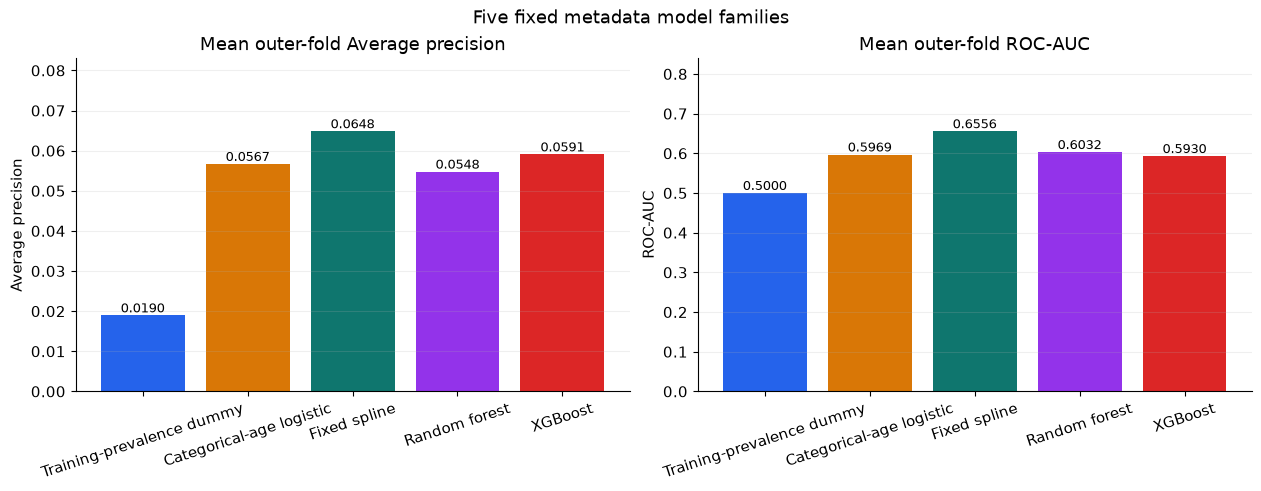

In [3]:
display(metrics.loc[metrics.scope.ne("fold")].round(5))
finish_figure(metric_bar_figure(metrics, names, "Five fixed metadata model families"), "metadata_five_model_scores")

## 3. Read variation across the preserved patient folds

A score can change because different held-out patients carry different malignant cases, ages and sites. These lines connect the same model across the five patient folds; they are not a learning curve or five independent datasets.

average_precision                                           \
model categorical_logistic   dummy random_forest spline_raw xgboost   
fold                                                                  
0.0                 0.0442  0.0179        0.0415     0.0662  0.0522   
1.0                 0.0488  0.0190        0.0559     0.0460  0.0623   
2.0                 0.0327  0.0196        0.0324     0.0373  0.0264   
3.0                 0.0663  0.0182        0.0609     0.0624  0.0690   
4.0                 0.0915  0.0200        0.0832     0.1122  0.0855   

                   roc_auc                                         
model categorical_logistic dummy random_forest spline_raw xgboost  
fold                                                               
0.0                 0.6443   0.5        0.6487     0.7944  0.6423  
1.0                 0.5042   0.5        0.5025     0.5588  0.5236  
2.0                 0.5513   0.5        0.5802     0.6311  0.5001  
3.0                 0.7051   0.5        0.6661     0.6840  0.7243  
4.0                 0.5798   0.5        0.6186     0.6098  0.5749

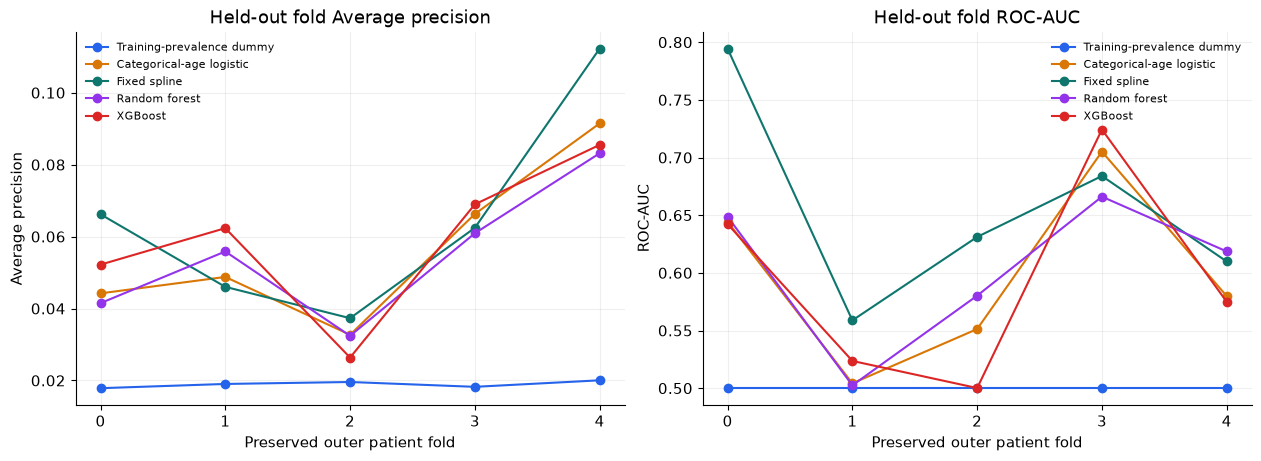

In [4]:
fold_metrics = metrics.loc[metrics.scope.eq("fold")]
display(fold_metrics.pivot(index="fold", columns="model", values=["average_precision", "roc_auc"]).round(4))
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5), layout="constrained")
for index, name in enumerate(names):
    rows = fold_metrics.loc[fold_metrics.model.eq(name)]
    for ax, metric in zip(axes, ["average_precision", "roc_auc"]):
        ax.plot(rows.fold, rows[metric], "o-", color=COLORS[index], label=LABELS[name])
for ax, label in zip(axes, ["Average precision", "ROC-AUC"]):
    ax.set(xlabel="Preserved outer patient fold", ylabel=label, title="Held-out fold " + label, xticks=range(5))
    ax.grid(alpha=.2); ax.legend(frameon=False, fontsize=8)
finish_figure(fig, "metadata_fold_variation")

## 4. Read the model ROC and PR curves

Each pooled curve traces a changing cutoff on held-out predictions. Curves can cross, meaning one method is better in one recall range and worse in another. PR is focused to 0–30% precision to reveal the low-prevalence trade-offs; the complete AP still uses the entire curve.

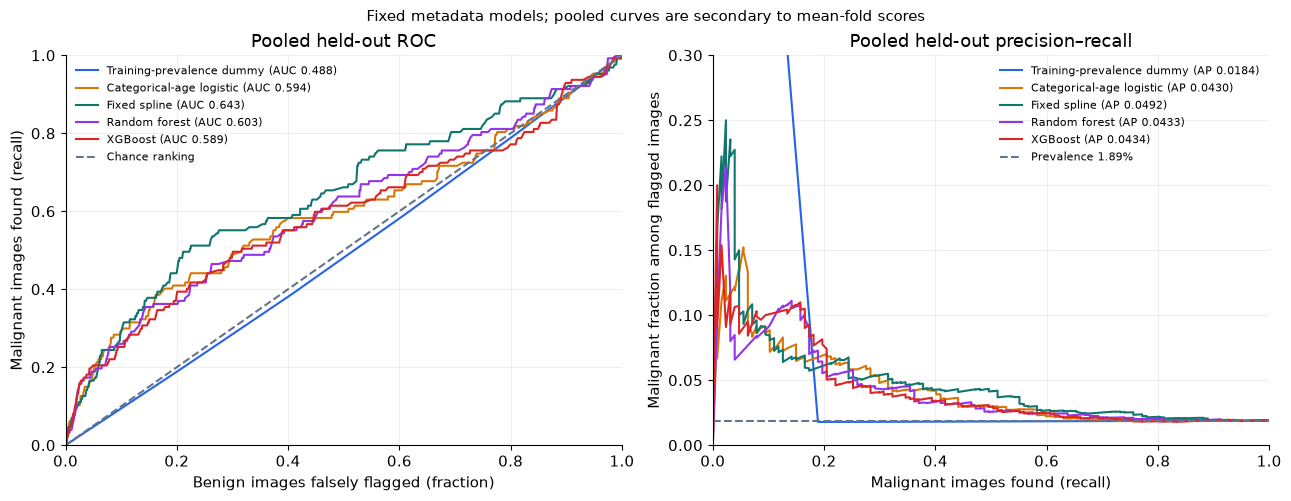

In [5]:
finish_figure(curve_figure(frame, scores, names, "Fixed metadata models", pr_limit=.30), "metadata_five_model_curves")

## 5. Inspect the learned nonlinear age relationship

Use the five saved outer-training spline models, without fitting all development patients. Hold site at torso and sex at the two recorded values while varying age. The line averages model predictions and shading spans the five fits. These conditional profiles are descriptive, omit lesion appearance and do not show a causal age effect or a risk for an actual patient.

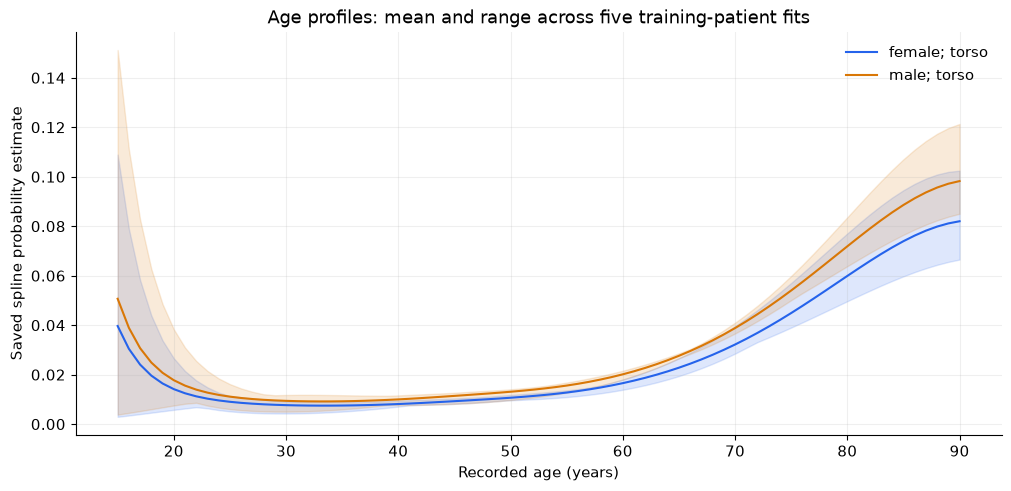

In [6]:
coefficients, importances, age_profiles = estimator_diagnostics(meta)
summary = age_profiles.groupby(["sex", "age"]).probability.agg(["mean", "min", "max"]).reset_index()
fig, ax = plt.subplots(figsize=(10, 4.8), layout="constrained")
for index, (sex, rows) in enumerate(summary.groupby("sex")):
    ax.plot(rows.age, rows["mean"], color=COLORS[index], label=f"{sex}; torso")
    ax.fill_between(rows.age, rows["min"], rows["max"], alpha=.15, color=COLORS[index])
ax.set(xlabel="Recorded age (years)", ylabel="Saved spline probability estimate", title="Age profiles: mean and range across five training-patient fits")
ax.legend(frameon=False); ax.grid(alpha=.2)
finish_figure(fig, "metadata_nonlinear_age_profiles")

## 6. Compare the seven original feature ablations

Each partial feature set uses the same spline/logistic procedure and patient folds. The all-feature row reuses the exact fixed-spline predictions. A lower score after dropping a field describes its value in this procedure; it does not prove a causal effect. Correlated fields and changing prevalence complicate interpretation.

,model,scope,fold,average_precision,roc_auc,log_loss,brier
5,ablation_sex,mean_fold,NaN,0.02191,0.55190,0.09382,0.01859
6,ablation_sex,pooled,NaN,0.01972,0.51909,0.09378,0.01858
12,ablation_age,mean_fold,NaN,0.04577,0.65507,0.09156,0.01845
13,ablation_age,pooled,NaN,0.04125,0.62865,0.09148,0.01844
19,ablation_site,mean_fold,NaN,0.02905,0.56252,0.09272,0.01853
20,ablation_site,pooled,NaN,0.02709,0.54784,0.09268,0.01852
26,ablation_sex_age,mean_fold,NaN,0.04564,0.63125,0.09189,0.01846
27,ablation_sex_age,pooled,NaN,0.04035,0.61367,0.09182,0.01845
33,ablation_sex_site,mean_fold,NaN,0.03366,0.58643,0.09261,0.01852
34,ablation_sex_site,pooled,NaN,0.03028,0.57764,0.09259,0.01851


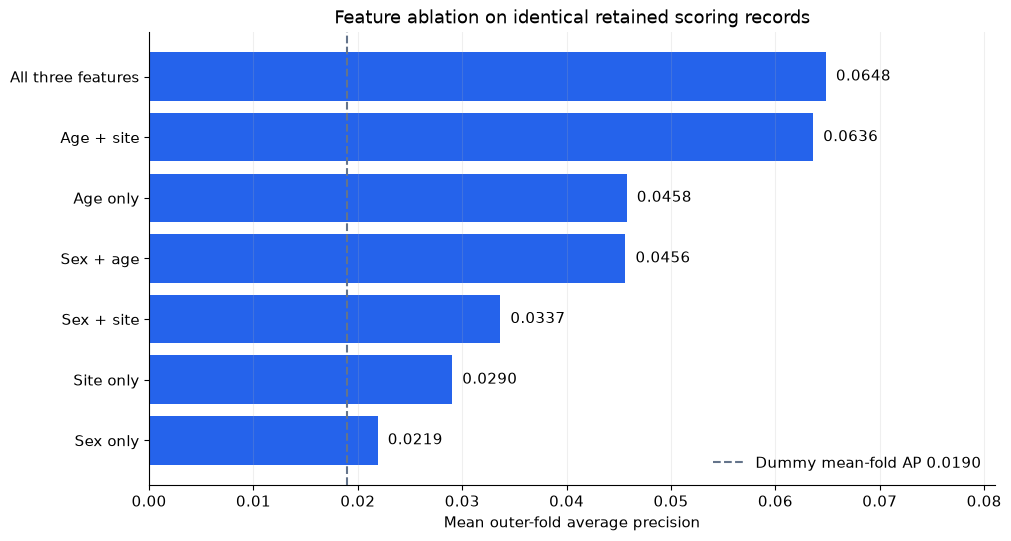

In [7]:
ablation_names = ["ablation_sex", "ablation_age", "ablation_site", "ablation_sex_age", "ablation_sex_site", "ablation_age_site", "ablation_all_features"]
ablation_metrics = metric_table(frame, scores, ablation_names)
display(ablation_metrics.loc[ablation_metrics.scope.ne("fold")].round(5))
assert np.allclose(scores["ablation_all_features"], scores["spline_raw"], rtol=0, atol=1e-14)
selected = ablation_metrics.loc[ablation_metrics.scope.eq("mean_fold")].sort_values("average_precision")
dummy_ap = metrics.loc[metrics.model.eq("dummy") & metrics.scope.eq("mean_fold"), "average_precision"].iloc[0]
fig, ax = plt.subplots(figsize=(10, 5.3), layout="constrained")
ax.barh([LABELS[name] for name in selected.model], selected.average_precision, color="#2563eb")
ax.axvline(dummy_ap, color="#64748b", linestyle="--", label=f"Dummy mean-fold AP {dummy_ap:.4f}")
for index, value in enumerate(selected.average_precision): ax.text(value, index, f"  {value:.4f}", va="center")
ax.set(xlabel="Mean outer-fold average precision", title="Feature ablation on identical retained scoring records", xlim=(0, float(selected.average_precision.max()) * 1.25))
ax.legend(frameon=False); ax.grid(axis="x", alpha=.2)
finish_figure(fig, "metadata_seven_feature_ablations")

## 7. Inspect tree importances with the proper cautions

Sum encoded-column importances back to age, sex and site. Forest values use impurity-based importance; XGBoost uses its saved normalised tree importance. Many age categories can receive more opportunities for splits. These measures are associations within fitted trees and cannot establish out-of-sample field importance or causation; compare fields within a model, not magnitudes across algorithms.

,model,feature,mean,std
0,random_forest,age_approx,0.5374,0.0269
1,random_forest,anatom_site_general_challenge,0.3419,0.0296
2,random_forest,sex,0.1207,0.0115
3,xgboost,age_approx,0.7323,0.0190
4,xgboost,anatom_site_general_challenge,0.2393,0.0132
5,xgboost,sex,0.0284,0.0094


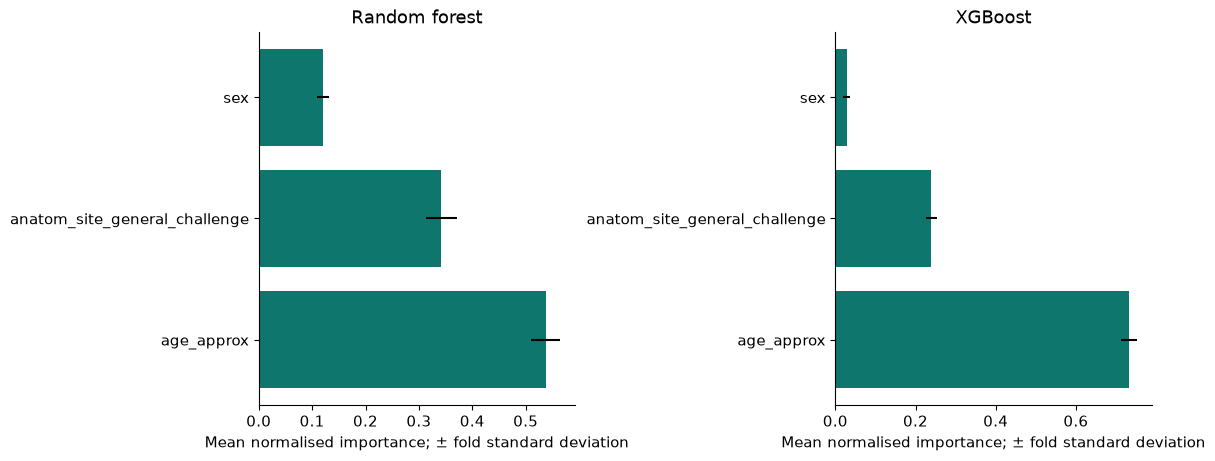

In [8]:
summary = importances.groupby(["model", "feature"]).importance.agg(["mean", "std"]).reset_index()
display(summary.round(4))
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5), layout="constrained")
for ax, model in zip(axes, ["random_forest", "xgboost"]):
    rows = summary.loc[summary.model.eq(model)]
    ax.barh(rows.feature, rows["mean"], xerr=rows["std"], color="#0f766e")
    ax.set(xlabel="Mean normalised importance; ± fold standard deviation", title=LABELS[model])
finish_figure(fig, "metadata_saved_tree_importances")

## 8. Reproduce the exploratory confusion-matrix comparison

Original notebook 05 selected each learned model's balanced-accuracy cutoff from the same OOF labels it reported. Retain that educational illustration here as explicitly secondary. These cutoffs never replace training-only decision rules, and matrices do not establish clinical usefulness. The dummy remains fixed at 0.50.

,model,cutoff,role,balanced_accuracy,TP,FP,TN,FN,sensitivity,specificity,precision,flagged_fraction
0,dummy,0.5,Fixed descriptive cutoff,0.5,0,0,6579,127,0.0,1.0,NaN,0.0
1,categorical_logistic,0.5,Fixed descriptive cutoff,0.5,0,0,6579,127,0.0,1.0,NaN,0.0
2,spline_raw,0.5,Fixed descriptive cutoff,0.5,0,0,6579,127,0.0,1.0,NaN,0.0
3,random_forest,0.5,Fixed descriptive cutoff,0.5,0,0,6579,127,0.0,1.0,NaN,0.0
4,xgboost,0.5,Fixed descriptive cutoff,0.5,0,0,6579,127,0.0,1.0,NaN,0.0


,model,cutoff,role,balanced_accuracy,TP,FP,TN,FN,sensitivity,specificity,precision,flagged_fraction
0,dummy,0.50000,Fixed descriptive cutoff,0.50000,0,0,6579,127,0.00000,1.00000,NaN,0.00000
1,categorical_logistic,0.02719,OOF-selected illustration; selection and asses...,0.61187,51,1170,5409,76,0.40157,0.82216,0.04177,0.18208
2,spline_raw,0.02274,OOF-selected illustration; selection and asses...,0.64312,65,1484,5095,62,0.51181,0.77443,0.04196,0.23099
3,random_forest,0.02846,OOF-selected illustration; selection and asses...,0.60512,45,948,5631,82,0.35433,0.85591,0.04532,0.14808
4,xgboost,0.01986,OOF-selected illustration; selection and asses...,0.59778,63,1977,4602,64,0.49606,0.69950,0.03088,0.30421


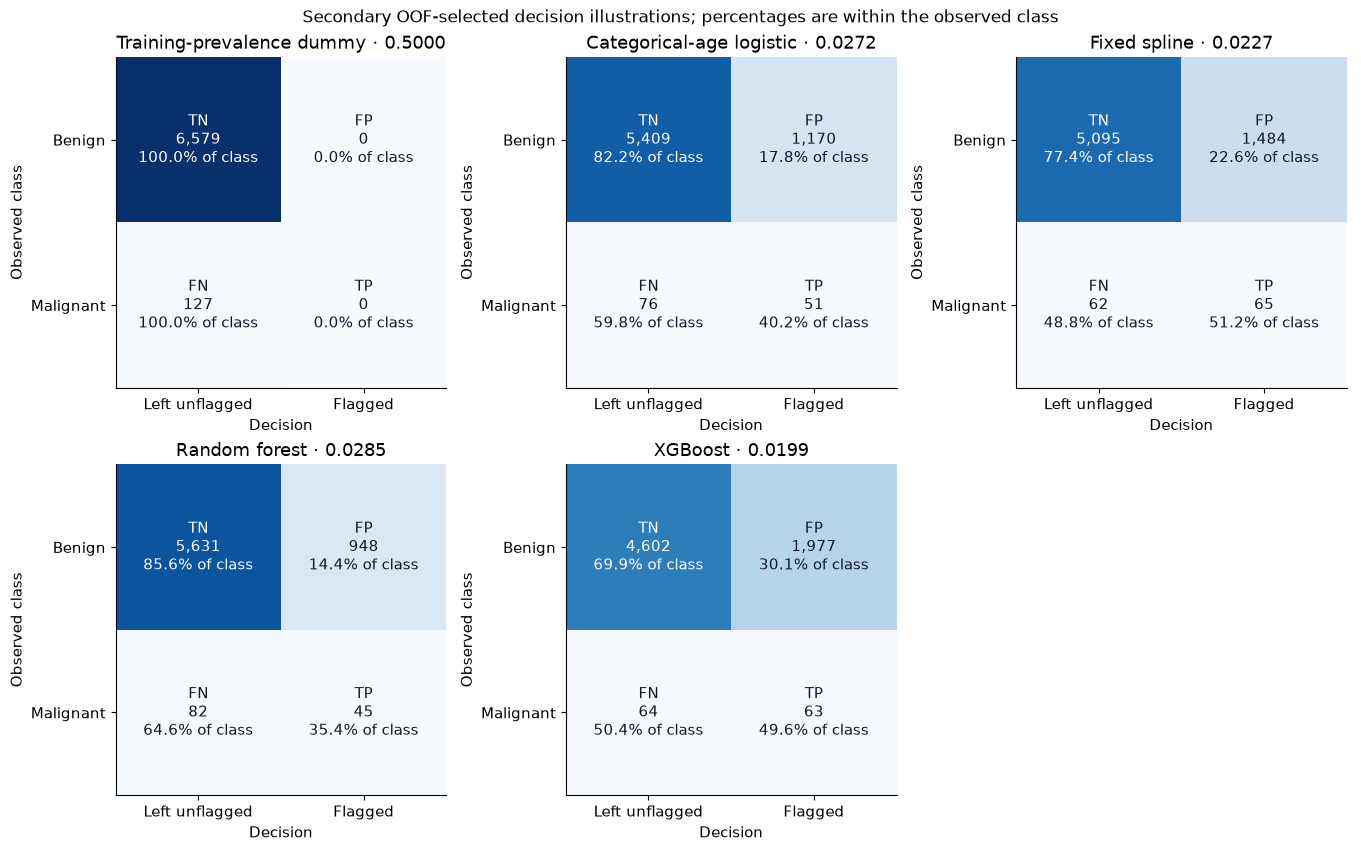

In [9]:
fixed = cutoff_table(frame, scores, names)
illustrative = cutoff_table(frame, scores, names, exploratory=True)
display(fixed.round(5)); display(illustrative.round(5))
scenarios = [(LABELS[row.model] + f" · {row.cutoff:.4f}", scores[row.model] >= row.cutoff) for row in illustrative.itertuples()]
finish_figure(confusion_figure(frame.target, scenarios, "Secondary OOF-selected decision illustrations"), "metadata_exploratory_confusions")

## 9. Collect the supported findings

Keep the original fixed spline as the predeclared metadata comparator even if a secondary model leads one score. Read AP, AUC, fold variation and review workload together; do not promote a model from whichever table looks favourable.

In [10]:
primary = metrics.loc[metrics.scope.eq("mean_fold")].sort_values("average_precision", ascending=False)
display(primary[["model", "average_precision", "roc_auc", "log_loss", "brier"]].round(5))
display(Markdown("The clean five-model results and feature ablations are complete development comparisons. Calibration and patient intervals follow in notebook 08; the reserved test remains untouched."))

,model,average_precision,roc_auc,log_loss,brier
19,spline_raw,0.06484,0.65563,0.09101,0.01842
33,xgboost,0.05907,0.59304,0.09385,0.01851
12,categorical_logistic,0.05669,0.59695,0.09244,0.01849
26,random_forest,0.05477,0.60319,0.09195,0.01845
5,dummy,0.01895,0.50000,0.09393,0.01859


The clean five-model results and feature ablations are complete development comparisons. Calibration and patient intervals follow in notebook 08; the reserved test remains untouched.

## Interpretation boundary

These are development results. Patient grouping protects separation between fitting and validation; bootstrap intervals condition on saved models. Sparse subgroups and selected inner-validation pilots cannot establish a final winner. No reserved-test conclusion is made.